# Prepayment Speed vs. Borrower & Loan Characteristics (1D and 2D)

Loan-level analysis on a **sample** of Fannie Mae `data/fannie/Performance_All.zip` 

In [1]:
import sys
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "source"))
from load_data import FIELDS, N_FIELDS, PERFORMANCE_ZIP, list_members, load_performance_sample

MB_PER_FILE = 80        # head of each quarterly file to read (~750k loans total at 80 MB)
CACHE = ROOT / "data" / "fannie" / "processed" / f"perf_sample_{MB_PER_FILE}mb.parquet"
MIN_LOAN_MONTHS = 2_000  # cells with less exposure are blanked out
RATE_LAG = 1             # months between prevailing rate and payoff month

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)

polars.config.Config

In [2]:
# Plot style: categorical slots in fixed order, one-hue sequential ramp, recessive axes
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUES = LinearSegmentedColormap.from_list("blues", [
    "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
BLUES.set_bad("#f0efec")
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e0"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=SERIES),
    "axes.axisbelow": True,
    "lines.linewidth": 2, "lines.markersize": 5,
    "legend.frameon": False, "legend.fontsize": 8.5,
})

## 1. Load the sample and check the reference layout against the zip

The first run reads the zip (about 20 s at 80 MB/file) and caches the result to parquet. Later runs load the cache.

In [3]:
members = list_members()
print(f"{len(members)} quarterly files: {members[0]} ... {members[-1]}")

raw = load_performance_sample(CACHE, mb_per_file=MB_PER_FILE)
print(f"{raw.height:,} loan-months | {raw['loan_id'].n_unique():,} loans | {raw.estimated_size('mb'):,.0f} MB in memory")

105 quarterly files: 2000Q1.csv ... 2026Q1.csv


29,546,077 loan-months | 746,494 loans | 4,085 MB in memory


**Layout validation.** `load_data.py` already raises an error if any file has a field count other than 113. Below, each mapped field is tested against what the PDF says it should contain.

In [4]:
def month_idx(col):
    # MMYYYY -> months since year 0
    return pl.col(col).str.slice(2, 4).cast(pl.Int32) * 12 + pl.col(col).str.slice(0, 2).cast(pl.Int32) - 1

chk = raw.with_columns(
    t=month_idx("rep_period"), fpd=month_idx("first_pay_date"), od=month_idx("orig_date"))
mmyyyy = r"^(0[1-9]|1[0-2])(19|20)\d{2}$"
zbc_codes = ["01", "02", "03", "06", "09", "15", "16", "96", "97", "98"]

checks = {
    "f3/14/15 dates are MMYYYY":              chk.select(pl.all_horizontal(pl.col(c).str.contains(mmyyyy) for c in ["rep_period", "orig_date", "first_pay_date"]).all()).item(),
    "f8 note rate in (0, 15)":                chk.select(pl.col("orig_rate").is_between(0.01, 15).all()).item(),
    "f13 term in months, <= 360":             chk.select(pl.col("orig_term").is_between(60, 480).all()).item(),
    "f16 loan age = rep - first pay + 1":     chk.filter(pl.col("loan_age").is_not_null()).select((pl.col("loan_age") == pl.col("t") - pl.col("fpd") + 1).mean()).item(),
    "f15 first pay 1-2 mo after f14 orig":    chk.select((pl.col("fpd") - pl.col("od")).is_between(1, 2).mean()).item(),
    "f20 LTV in [1, 200]":                    chk.select(pl.col("ltv").is_between(1, 200).all()).item(),
    "f21 CLTV >= LTV":                        chk.filter(pl.col("cltv").is_not_null()).select((pl.col("cltv") >= pl.col("ltv")).mean()).item(),
    "f23 DTI in [0, 65]":                     chk.select(pl.col("dti").drop_nulls().is_between(0, 65).all()).item(),
    "f24 FICO in [300, 850]":                 chk.select(pl.col("fico").drop_nulls().is_between(300, 850).all()).item(),
    "f111 classic FICO in [300, 850]":        chk.select(pl.col("fico_classic_orig").drop_nulls().is_between(300, 850).all()).item(),
    "f27/f30 purpose & occupancy codes":      chk.select(pl.col("loan_purpose").cast(pl.Utf8).is_in(["P", "C", "R", "U"]).all() & pl.col("occupancy").cast(pl.Utf8).is_in(["P", "S", "I", "U"]).all()).item(),
    "f35 amortization type is FRM":           chk.select((pl.col("amort_type").cast(pl.Utf8) == "FRM").all()).item(),
    "f44 zero-balance codes are valid":       chk.select(pl.col("zero_bal_code").drop_nulls().cast(pl.Utf8).is_in(zbc_codes).all()).item(),
    "f46 UPB@removal present iff f44 set":    chk.select((pl.col("upb_at_removal").is_not_null() == pl.col("zero_bal_code").is_not_null()).mean()).item(),
}
last_t = chk.group_by("loan_id").agg(t_max=pl.col("t").max())
zb = chk.filter(pl.col("zero_bal_code").is_not_null()).join(last_t, on="loan_id")
checks["f44 set only on the loan's last row"] = zb.select((pl.col("t") == pl.col("t_max")).mean()).item()

pl.DataFrame({"check": list(checks), "result": [f"{v:.4f}" if isinstance(v, float) else str(v) for v in checks.values()]})

check,result
str,str
"""f3/14/15 dates are MMYYYY""","""True"""
"""f8 note rate in (0, 15)""","""True"""
"""f13 term in months, <= 360""","""True"""
"""f16 loan age = rep - first pay…","""1.0000"""
"""f15 first pay 1-2 mo after f14…","""0.9714"""
"""f20 LTV in [1, 200]""","""True"""
"""f21 CLTV >= LTV""","""0.9999"""
"""f23 DTI in [0, 65]""","""True"""
"""f24 FICO in [300, 850]""","""True"""


In [5]:
# FICO coverage by reporting year: field 24 vs. field 111 ("Origination Classic FICO", populated from Dec 2025 activity)
(chk.with_columns(rep_year=(pl.col("t") // 12))
    .group_by("rep_year").agg(f24=pl.col("fico").is_not_null().mean(), f111=pl.col("fico_classic_orig").is_not_null().mean(),
                              either=pl.coalesce("fico", "fico_classic_orig").is_not_null().mean())
    .sort("rep_year").tail(6))

rep_year,f24,f111,either
i32,f64,f64,f64
2021,0.99884,0.0,0.99884
2022,0.998929,0.0,0.998929
2023,0.998857,0.0,0.998857
2024,0.998712,0.0,0.998712
2025,0.998272,0.098761,0.998363
2026,0.667425,0.998764,0.998764


**Layout verdict:** the PDF field positions line up with the zip. There are 113 fields per row, matching PDF fields 1-113. Field 114 (VantageScore 4.0) only starts with the May 2026 activity period and is not in this extract. Field 1 (Reference Pool ID) is blank, as expected for the SF Loan Performance dataset.

From the Dec 2025 activity period onward, field 24 (FICO at origination) is only partly populated and field 111 (Classic FICO) is filled instead. We therefore use `coalesce(f24, f111)`.

## 2. Build loan-month panel, refi-incentive proxy and buckets

In [6]:
panel = (
    raw.lazy()
    .filter(pl.col("orig_term") == 360)
    .with_columns(t=month_idx("rep_period"), fpd=month_idx("first_pay_date"), od=month_idx("orig_date"))
    .with_columns(
        age=pl.col("t") - pl.col("fpd") + 1,          # f16 is blank on termination rows
        fico=pl.coalesce("fico", "fico_classic_orig"),
        prepay=(pl.col("zero_bal_code") == "01"),
        # balance exposed this month: f46 on the exit row, current UPB otherwise (masked to 0 in months 1-6 -> original UPB)
        exposure=pl.when(pl.col("zero_bal_code").is_not_null()).then(pl.col("upb_at_removal"))
                   .when(pl.col("cur_upb") > 0).then(pl.col("cur_upb"))
                   .otherwise(pl.col("orig_upb")),
    )
    .filter(pl.col("age") >= 1)
    .with_columns(prepaid=pl.when(pl.col("prepay")).then(pl.col("exposure")).otherwise(0.0))
    .select("loan_id", "t", "od", "age", "orig_rate", "orig_upb", "ltv", "cltv", "dti", "fico", "num_borrowers",
            "first_time_buyer", "loan_purpose", "property_type", "occupancy", "channel", "num_units", "state",
            "prepay", "exposure", "prepaid")
    .collect()
)
del raw, chk
print(f"{panel.height:,} 30Y loan-months | {panel['loan_id'].n_unique():,} loans | {panel['prepay'].sum():,} voluntary payoffs")

21,659,696 30Y loan-months | 605,535 loans | 308,402 voluntary payoffs


In [7]:
# Prevailing-rate proxy: balance-weighted note rate of 30Y loans originated in each month (one row per loan)
orig = panel.group_by("loan_id").agg(pl.col("od", "orig_rate", "orig_upb").first())
mkt = (orig.group_by("od")
       .agg(mkt_rate=(pl.col("orig_rate") * pl.col("orig_upb")).sum() / pl.col("orig_upb").sum(), n_orig=pl.len())
       .filter(pl.col("n_orig") >= 30).sort("od"))
months = pl.DataFrame({"od": np.arange(mkt["od"].min(), panel["t"].max() + 1, dtype=np.int32)})
mkt = months.join(mkt, on="od", how="left").with_columns(pl.col("mkt_rate").interpolate().forward_fill())

panel = (panel.join(mkt.select(t=pl.col("od") + RATE_LAG, mkt_rate="mkt_rate"), on="t", how="left")
              .with_columns(incentive=pl.col("orig_rate") - pl.col("mkt_rate")))
print(f"incentive missing on {panel['incentive'].is_null().mean():.2%} of rows")

incentive missing on 0.00% of rows


In [8]:
def cut(col, breaks, labels):
    # left-closed bins; returns an Enum, so buckets sort in their natural order
    return pl.col(col).cast(pl.Float64).bin_intervals([float(b) for b in breaks], labels=labels)

BUCKETS = {
    "fico_b":   ("fico",      [620, 660, 700, 740, 780, 800], ["<620", "620-659", "660-699", "700-739", "740-779", "780-799", "800+"]),
    "ltv_b":    ("ltv",       [60.01, 70.01, 75.01, 80.01, 85.01, 90.01, 95.01], ["<=60", "60-70", "70-75", "75-80", "80-85", "85-90", "90-95", ">95"]),
    "cltv_b":   ("cltv",      [60.01, 70.01, 80.01, 90.01, 95.01], ["<=60", "60-70", "70-80", "80-90", "90-95", ">95"]),
    "dti_b":    ("dti",       [20, 30, 36, 43, 50], ["<20", "20-29", "30-35", "36-42", "43-49", "50+"]),
    "upb_b":    ("orig_upb",  [1e5, 1.5e5, 2e5, 3e5, 4e5, 5.5e5], ["<100k", "100-150k", "150-200k", "200-300k", "300-400k", "400-550k", "550k+"]),
    "age_b":    ("age",       [7, 13, 25, 37, 61, 121], ["1-6", "7-12", "13-24", "25-36", "37-60", "61-120", "121+"]),
    "inc_b":    ("incentive", list(np.round(np.arange(-2.0, 2.51, 0.25), 2)), None),
    "rate_b":   ("orig_rate", [3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7, 7.5, 8], ["<3", "3-3.5", "3.5-4", "4-4.5", "4.5-5", "5-5.5", "5.5-6", "6-6.5", "6.5-7", "7-7.5", "7.5-8", "8+"]),
}
inc_breaks = BUCKETS["inc_b"][1]
inc_labels = [f"<{inc_breaks[0]:+.2f}"] + [f"{a:+.2f}" for a in inc_breaks[:-1]] + [f">={inc_breaks[-1]:+.2f}"]
BUCKETS["inc_b"] = ("incentive", inc_breaks, inc_labels)
# numeric x for plotting incentive bins (bin midpoints)
INC_MID = dict(zip(inc_labels, [inc_breaks[0] - 0.125] + [a + 0.125 for a in inc_breaks[:-1]] + [inc_breaks[-1] + 0.125]))

panel = panel.with_columns(
    [cut(src, br, lb).alias(name) for name, (src, br, lb) in BUCKETS.items()]
    + [(pl.col("od") // 12).alias("vintage"),
       (pl.col("t") // 12).alias("rep_year"),
       pl.when(pl.col("num_borrowers") >= 2).then(pl.lit("2+")).otherwise(pl.lit("1")).alias("nborr_b"),
       # coarse regimes for small multiples
       cut("incentive", [0.0, 0.75], ["Out of the money (<0)", "Near the money (0-75bp)", "In the money (>75bp)"]).alias("inc_regime"),
       cut("fico", [680, 740, 780], ["<680", "680-739", "740-779", "780+"]).alias("fico_4"),
       cut("ltv", [60.01, 80.01, 90.01], ["<=60", "60-80", "80-90", ">90"]).alias("ltv_4"),
       cut("orig_upb", [1.5e5, 2.5e5, 4e5], ["<150k", "150-250k", "250-400k", "400k+"]).alias("upb_4"),
       cut("age", [13, 37, 61], ["1-12", "13-36", "37-60", "61+"]).alias("age_4"),
       cut("dti", [30, 43], ["<30", "30-42", "43+"]).alias("dti_3")]
)
panel.select("fico_b", "ltv_b", "dti_b", "upb_b", "age_b", "inc_b", "inc_regime").head()

fico_b,ltv_b,dti_b,upb_b,age_b,inc_b,inc_regime
enum,enum,enum,enum,enum,enum,enum
"""740-779""","""75-80""","""50+""","""<100k""","""1-6""","""-0.25""","""Out of the money (<0)"""
"""740-779""","""75-80""","""50+""","""<100k""","""1-6""","""-0.50""","""Out of the money (<0)"""
"""740-779""","""75-80""","""50+""","""<100k""","""1-6""","""-0.50""","""Out of the money (<0)"""
"""740-779""","""75-80""","""50+""","""<100k""","""1-6""","""-0.50""","""Out of the money (<0)"""
"""740-779""","""75-80""","""50+""","""<100k""","""1-6""","""-0.50""","""Out of the money (<0)"""


In [9]:
def cpr_table(frame, by, min_lm=MIN_LOAN_MONTHS):
    # Balance-weighted CPR (%) with a 95% band from the count-based binomial SE of SMM
    by = [by] if isinstance(by, str) else list(by)
    t = (frame.filter(pl.all_horizontal(pl.col(c).is_not_null() for c in by))
         .group_by(by)
         .agg(exposure=pl.col("exposure").sum(), prepaid=pl.col("prepaid").sum(),
              loan_months=pl.len(), payoffs=pl.col("prepay").sum())
         .with_columns(smm=pl.col("prepaid") / pl.col("exposure"),
                       se=(pl.col("payoffs") / pl.col("loan_months") * (1 - pl.col("payoffs") / pl.col("loan_months")) / pl.col("loan_months")).sqrt())
         .with_columns([(100 * (1 - (1 - (pl.col("smm") + k * 1.96 * pl.col("se")).clip(0, 1)) ** 12)).alias(n)
                        for k, n in [(0, "cpr"), (-1, "cpr_lo"), (1, "cpr_hi")]])
         .with_columns([pl.when(pl.col("loan_months") >= min_lm).then(pl.col(c)).alias(c) for c in ["cpr", "cpr_lo", "cpr_hi"]])
         .with_columns(bal_share=pl.col("exposure") / pl.col("exposure").sum())
         .sort(by))
    return t.drop("se", "smm")

overall = cpr_table(panel.with_columns(all=pl.lit("all")), "all")
overall

all,exposure,prepaid,loan_months,payoffs,cpr,cpr_lo,cpr_hi,bal_share
str,f64,f64,u32,u32,f64,f64,f64,f64
"""all""",4.5525e12,6.4276e10,21659696,308402,15.687153,15.635935,15.738342,1.0


## 3. Context: prepayment speeds and rates over time

Without this context, 1D cuts are easy to misread. Speeds are mostly driven by the rate cycle (2003, 2012, 2020-21 refi waves), and loan characteristics shift from one vintage to the next.

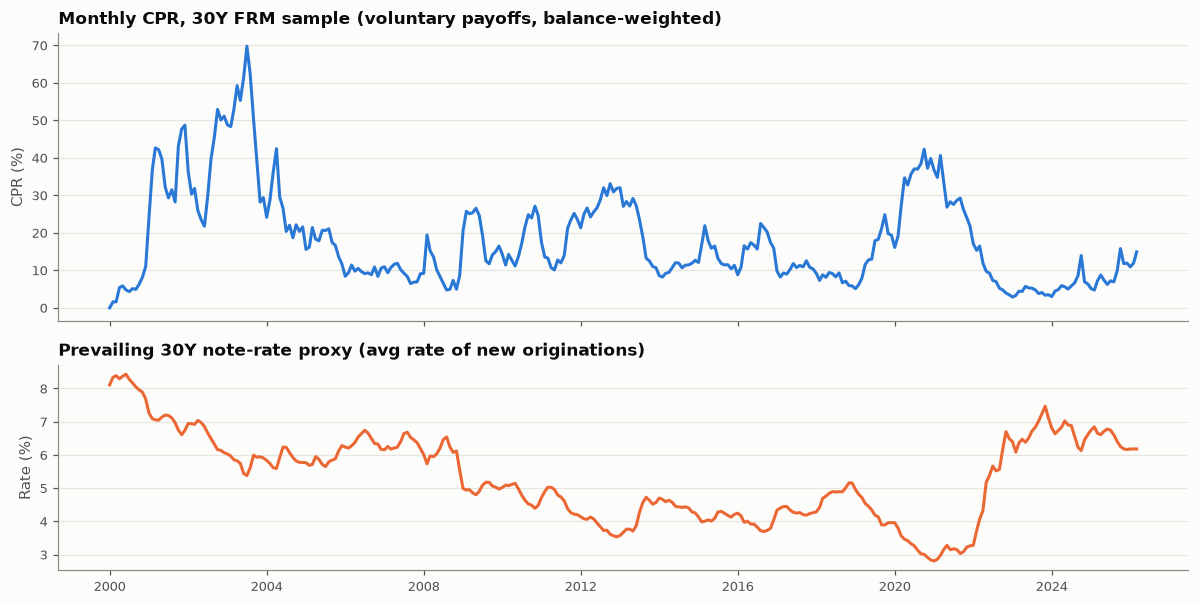

In [10]:
ts = cpr_table(panel, "t", min_lm=500).with_columns(date=pl.date(pl.col("t") // 12, pl.col("t") % 12 + 1, 1))
mk = mkt.with_columns(date=pl.date(pl.col("od") // 12, pl.col("od") % 12 + 1, 1)).filter(pl.col("date") >= ts["date"].min())

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True, height_ratios=[1.4, 1])
a1.plot(ts["date"], ts["cpr"], color=SERIES[0])
a1.set_title("Monthly CPR, 30Y FRM sample (voluntary payoffs, balance-weighted)", loc="left")
a1.set_ylabel("CPR (%)")
a2.plot(mk["date"], mk["mkt_rate"], color=SERIES[1])
a2.set_title("Prevailing 30Y note-rate proxy (avg rate of new originations)", loc="left")
a2.set_ylabel("Rate (%)")
fig.tight_layout()

## 4. One-dimensional analyses

Each panel plots CPR against a single characteristic and pools all months, vintages and rate environments. The shaded band is a 95% interval. The gray bars underneath show the share of exposed balance in each bucket.

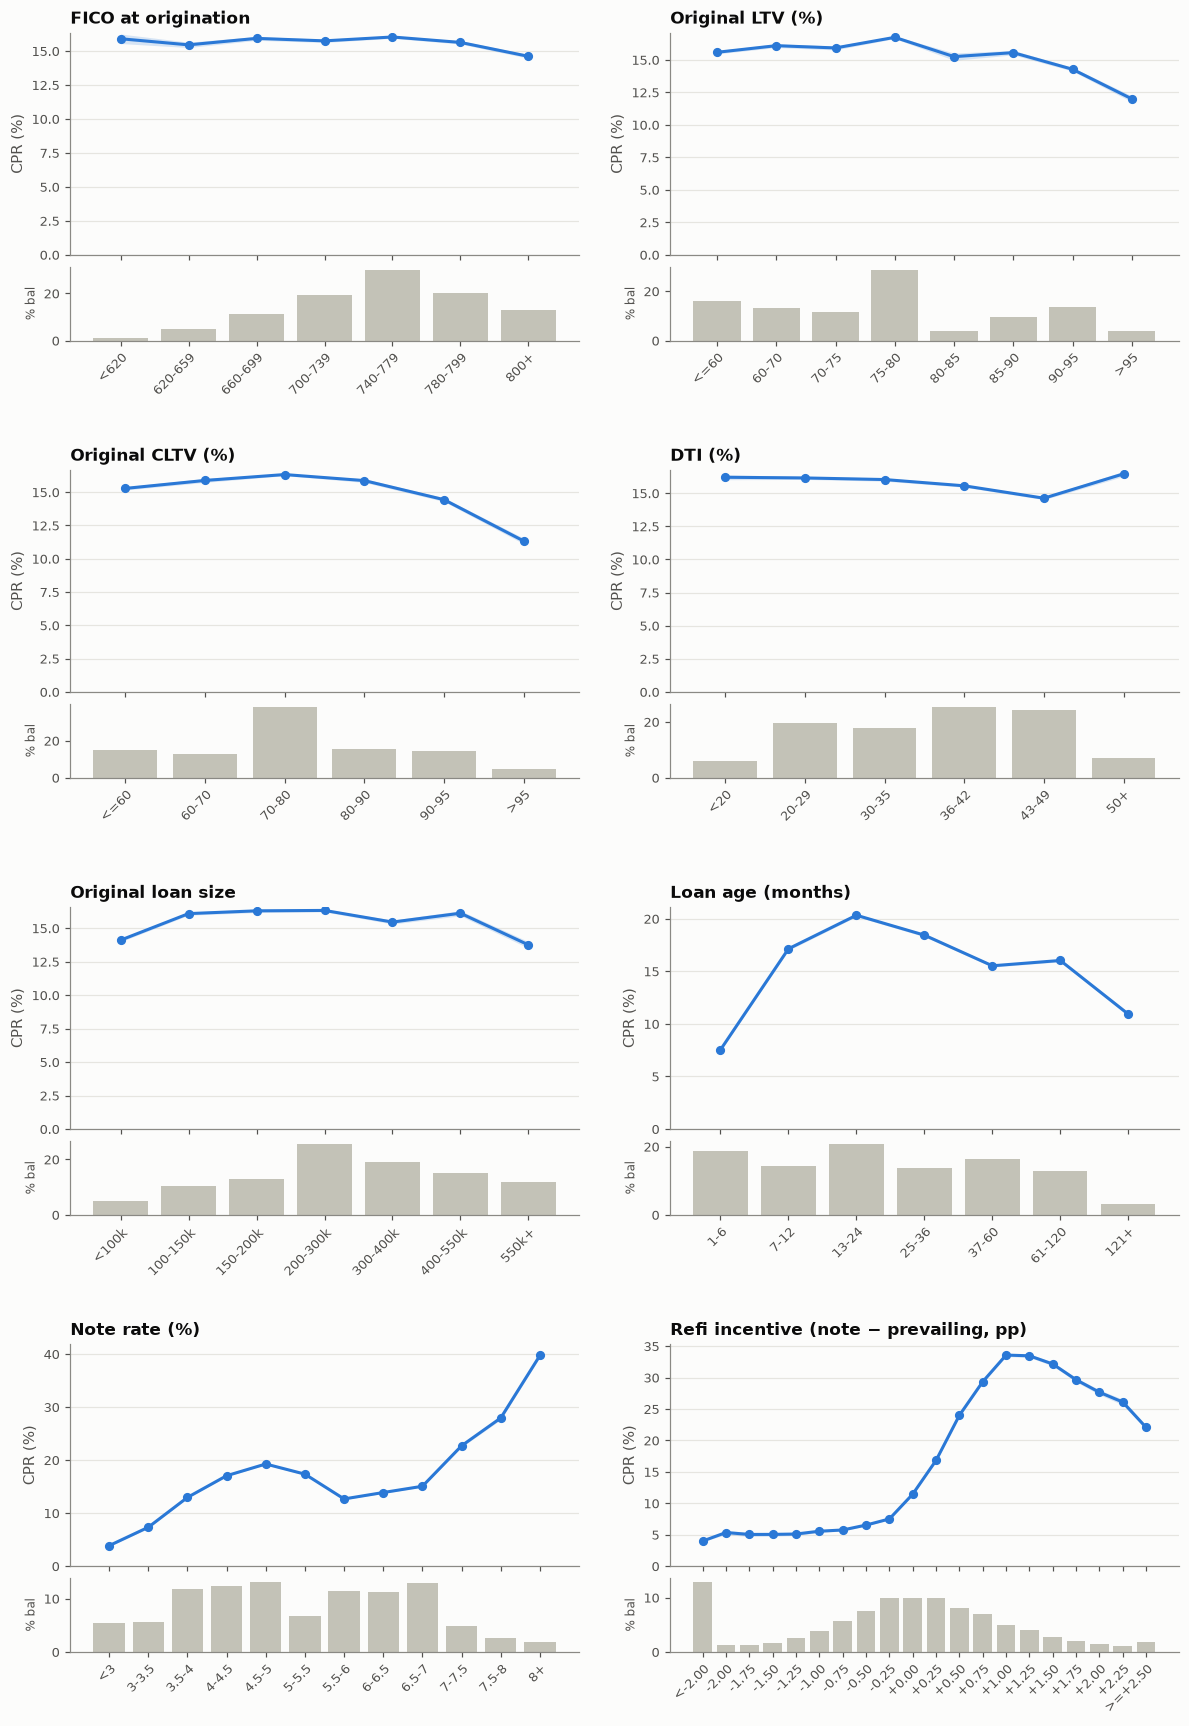

In [11]:
ONE_D = [
    ("fico_b", "FICO at origination"), ("ltv_b", "Original LTV (%)"), ("cltv_b", "Original CLTV (%)"),
    ("dti_b", "DTI (%)"), ("upb_b", "Original loan size"), ("age_b", "Loan age (months)"),
    ("rate_b", "Note rate (%)"), ("inc_b", "Refi incentive (note − prevailing, pp)"),
]

def plot_1d(ax_top, ax_bot, tbl, col, title):
    x = np.arange(tbl.height)
    ax_top.fill_between(x, tbl["cpr_lo"], tbl["cpr_hi"], color=SERIES[0], alpha=0.18, linewidth=0)
    ax_top.plot(x, tbl["cpr"], marker="o", color=SERIES[0])
    ax_top.set_title(title, loc="left")
    ax_top.set_ylabel("CPR (%)")
    ax_top.set_ylim(bottom=0)
    ax_bot.bar(x, 100 * tbl["bal_share"], color="#c3c2b7", width=0.8)
    ax_bot.set_ylabel("% bal", fontsize=8)
    ax_bot.set_xticks(x, tbl[col].cast(pl.Utf8), rotation=45, ha="right", rotation_mode="anchor")
    ax_bot.grid(False)

fig = plt.figure(figsize=(13, 16))
outer = fig.add_gridspec(4, 2, hspace=0.42, wspace=0.18, top=0.97, bottom=0.05)
for i, (col, title) in enumerate(ONE_D):
    inner = outer[i // 2, i % 2].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.08)
    at = fig.add_subplot(inner[0])
    ab = fig.add_subplot(inner[1], sharex=at)
    plt.setp(at.get_xticklabels(), visible=False)
    plot_1d(at, ab, cpr_table(panel, col), col, title)

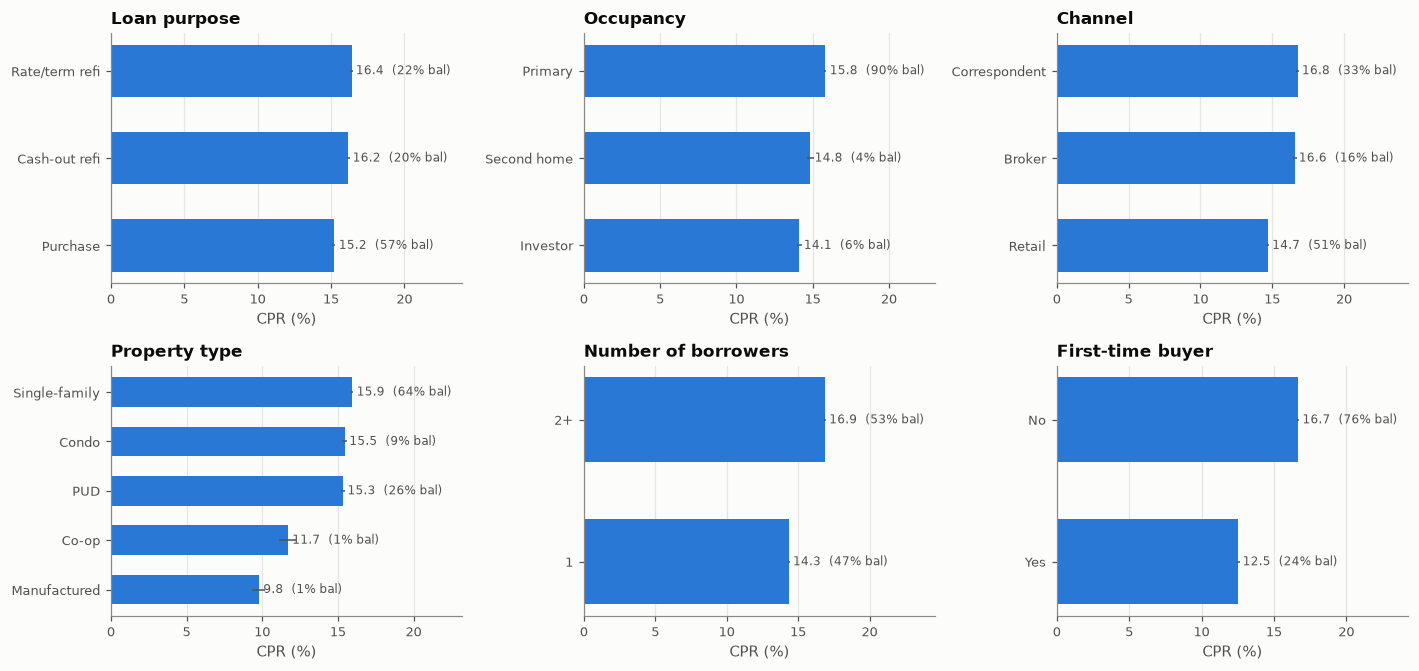

In [12]:
CAT_1D = [
    ("loan_purpose", "Loan purpose", {"P": "Purchase", "C": "Cash-out refi", "R": "Rate/term refi"}),
    ("occupancy", "Occupancy", {"P": "Primary", "S": "Second home", "I": "Investor"}),
    ("channel", "Channel", {"R": "Retail", "C": "Correspondent", "B": "Broker"}),
    ("property_type", "Property type", {"SF": "Single-family", "PU": "PUD", "CO": "Condo", "MH": "Manufactured", "CP": "Co-op"}),
    ("nborr_b", "Number of borrowers", {"1": "1", "2+": "2+"}),
    ("first_time_buyer", "First-time buyer", {"Y": "Yes", "N": "No"}),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2))
for ax, (col, title, names) in zip(axes.flat, CAT_1D):
    tbl = cpr_table(panel.with_columns(pl.col(col).cast(pl.Utf8)), col).filter(pl.col(col).is_in(list(names)))
    tbl = tbl.with_columns(label=pl.col(col).replace_strict(names)).sort("cpr")
    y = np.arange(tbl.height)
    ax.barh(y, tbl["cpr"], color=SERIES[0], height=0.6,
            xerr=[tbl["cpr"] - tbl["cpr_lo"], tbl["cpr_hi"] - tbl["cpr"]], error_kw=dict(ecolor=INK_2, lw=1))
    for yi, v, s in zip(y, tbl["cpr"], tbl["bal_share"]):
        ax.text(v + 0.3, yi, f"{v:.1f}  ({100*s:.0f}% bal)", va="center", fontsize=8, color=INK_2)
    ax.set_yticks(y, tbl["label"])
    ax.set_title(title, loc="left")
    ax.set_xlabel("CPR (%)")
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, tbl["cpr_hi"].max() * 1.45)
fig.tight_layout()

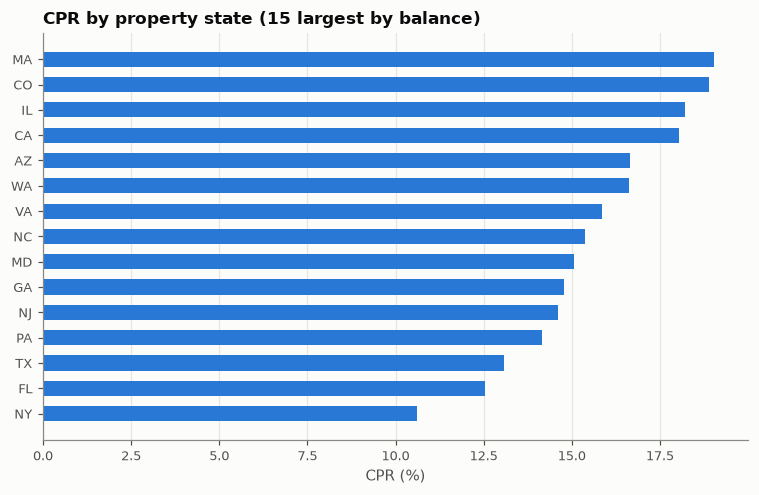

In [13]:
# State: top 15 by balance
st = cpr_table(panel.with_columns(pl.col("state").cast(pl.Utf8)), "state").sort("exposure", descending=True).head(15).sort("cpr")
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(st["state"], st["cpr"], color=SERIES[0], height=0.6)
ax.set_title("CPR by property state (15 largest by balance)", loc="left"); ax.set_xlabel("CPR (%)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
fig.tight_layout()

## 5. Two-dimensional analyses

### 5a. FICO × LTV

Unconditional heatmap first, then the same grid split by refi-incentive regime. The split shows whether the FICO/LTV pattern holds once rate incentive is held roughly fixed. Cells with fewer than `MIN_LOAN_MONTHS` loan-months are left blank.

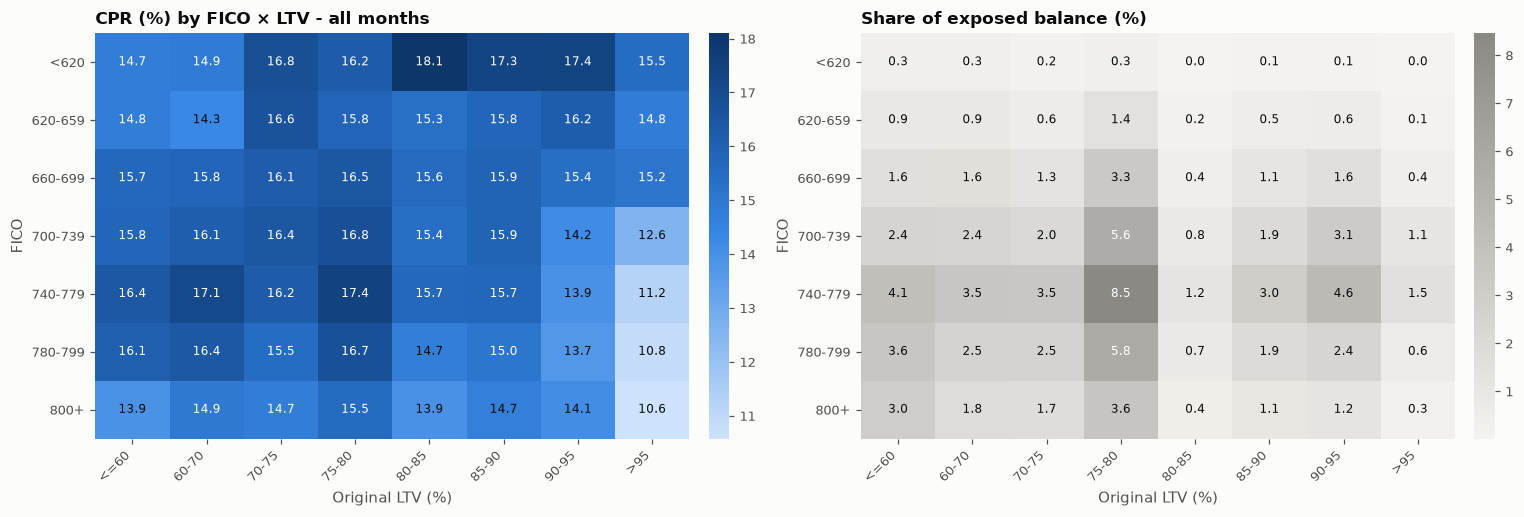

In [14]:
def heat(ax, tbl, row, col, val="cpr", fmt="{:.1f}", title="", cmap=BLUES, vmin=None, vmax=None, cbar=True):
    # bucket order comes from the Enum sort
    rows = [r for r in tbl.sort(row)[row].cast(pl.Utf8).unique(maintain_order=True)]
    cols = [c for c in tbl.sort(col)[col].cast(pl.Utf8).unique(maintain_order=True)]
    piv = tbl.with_columns(pl.col(row).cast(pl.Utf8), pl.col(col).cast(pl.Utf8)).pivot(on=col, index=row, values=val)
    piv = piv.join(pl.DataFrame({row: rows}), on=row, how="right").select([row] + [c for c in cols if c in piv.columns])
    Z = piv.drop(row).to_numpy().astype(float)
    M = np.ma.masked_invalid(Z)
    im = ax.imshow(M, cmap=cmap, aspect="auto", vmin=vmin, vmax=vmax)
    lo = vmin if vmin is not None else np.nanmin(Z)
    hi = vmax if vmax is not None else np.nanmax(Z)
    for i in range(Z.shape[0]):
        for j in range(Z.shape[1]):
            if np.isfinite(Z[i, j]):
                dark = (Z[i, j] - lo) / (hi - lo + 1e-9) > 0.55
                ax.text(j, i, fmt.format(Z[i, j]), ha="center", va="center", fontsize=8, color="white" if dark else INK)
    ax.set_xticks(range(Z.shape[1]), piv.columns[1:], rotation=45, ha="right")
    ax.set_yticks(range(Z.shape[0]), piv[row].to_list())
    ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(title, loc="left")
    if cbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03).outline.set_visible(False)
    return im

fl = cpr_table(panel, ["fico_b", "ltv_b"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8), width_ratios=[1, 1])
heat(a1, fl, "fico_b", "ltv_b", title="CPR (%) by FICO × LTV - all months")
heat(a2, fl.with_columns(bal_pct=100 * pl.col("bal_share")), "fico_b", "ltv_b", val="bal_pct", fmt="{:.1f}",
     title="Share of exposed balance (%)", cmap=LinearSegmentedColormap.from_list("g", ["#f4f3ef", "#8a8984"]))
for a in (a1, a2): a.set_xlabel("Original LTV (%)"); a.set_ylabel("FICO")
fig.tight_layout()

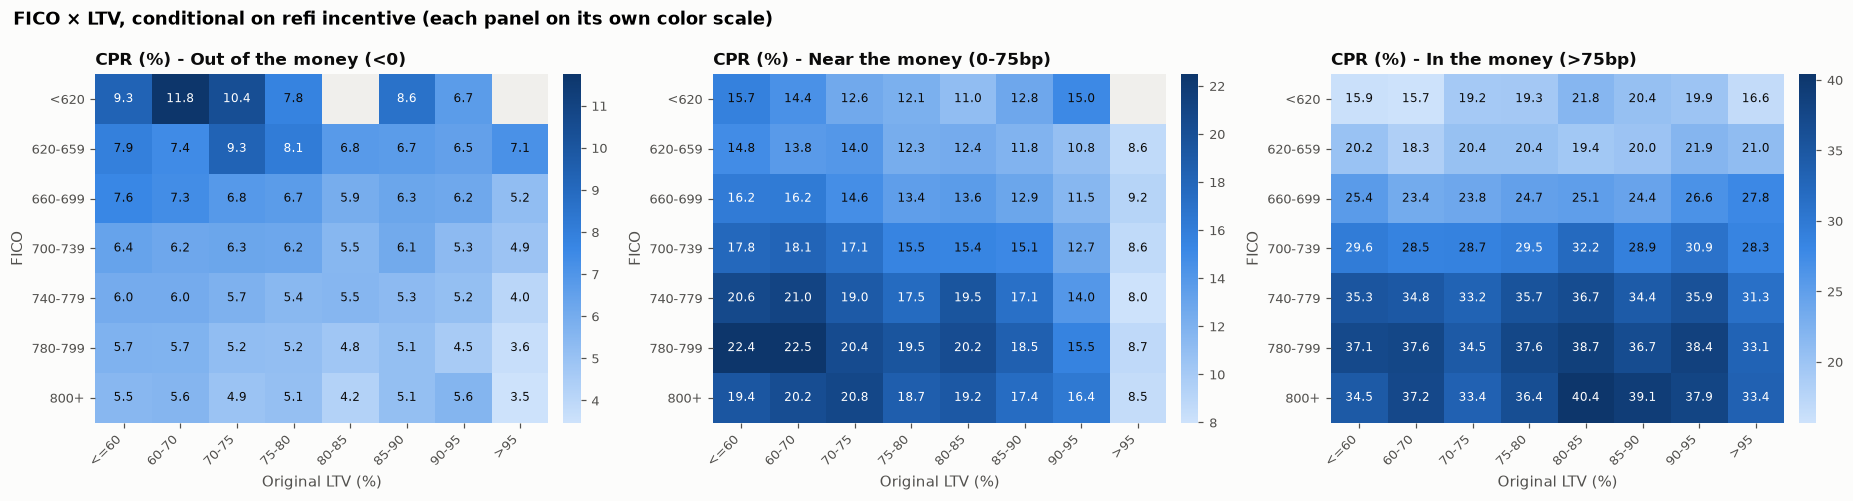

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (reg,) in zip(axes, panel.select(pl.col("inc_regime").unique().sort().drop_nulls()).iter_rows()):
    heat(ax, cpr_table(panel.filter(pl.col("inc_regime") == reg), ["fico_b", "ltv_b"]), "fico_b", "ltv_b", title=f"CPR (%) - {reg}")
    ax.set_xlabel("Original LTV (%)"); ax.set_ylabel("FICO")
fig.suptitle("FICO × LTV, conditional on refi incentive (each panel on its own color scale)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

### 5b. Refi S-curves by borrower and loan characteristics

CPR vs. refi incentive, one line per bucket of a second characteristic. These are the standard 2D views in prepayment modeling: a characteristic usually changes how strongly borrowers respond to an in-the-money rate, more than it changes baseline (turnover) speed.

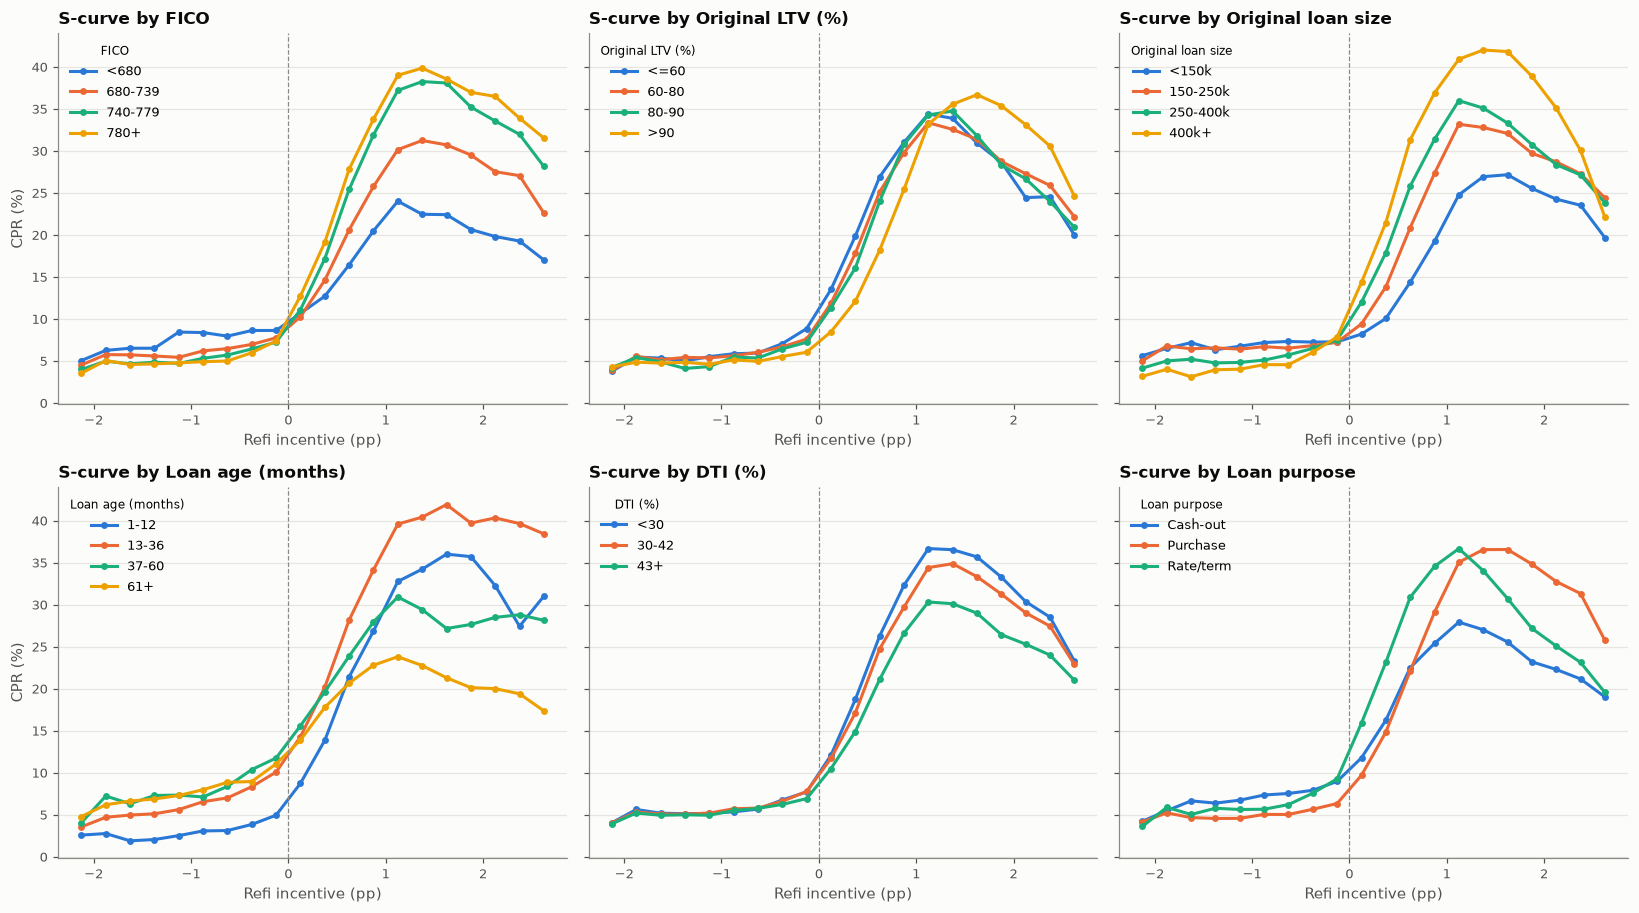

In [16]:
S_CURVES = [
    ("fico_4", "FICO"), ("ltv_4", "Original LTV (%)"), ("upb_4", "Original loan size"),
    ("age_4", "Loan age (months)"), ("dti_3", "DTI (%)"), ("loan_purpose", "Loan purpose"),
]
PURPOSE = {"P": "Purchase", "C": "Cash-out", "R": "Rate/term"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8.4), sharey=True)
for ax, (grp, title) in zip(axes.flat, S_CURVES):
    tbl = cpr_table(panel.with_columns(pl.col(grp).cast(pl.Utf8)), [grp, "inc_b"]).with_columns(
        x=pl.col("inc_b").cast(pl.Utf8).replace_strict(INC_MID, return_dtype=pl.Float64))
    order = panel.select(pl.col(grp).drop_nulls().unique().sort()).to_series().cast(pl.Utf8).to_list()
    if grp == "loan_purpose":
        order = [g for g in order if g in PURPOSE]
    for k, g in enumerate(order):
        d = tbl.filter(pl.col(grp) == g).sort("x")
        lab = PURPOSE.get(g, g) if grp == "loan_purpose" else g
        ax.plot(d["x"], d["cpr"], marker="o", markersize=3.5, color=SERIES[k], label=lab)
    ax.axvline(0, color=MUTED, lw=0.8, ls="--")
    ax.set_title(f"S-curve by {title}", loc="left")
    ax.set_xlabel("Refi incentive (pp)")
    ax.legend(loc="upper left", title=title, title_fontsize=8)
for ax in axes[:, 0]: ax.set_ylabel("CPR (%)")
fig.tight_layout()

### 5c. Other characteristic pairs

FICO × DTI, LTV × loan age, and loan size × incentive. The last one shows the loan-size effect: on larger loans a given rate gap saves more dollars, so refinancing pays off sooner.

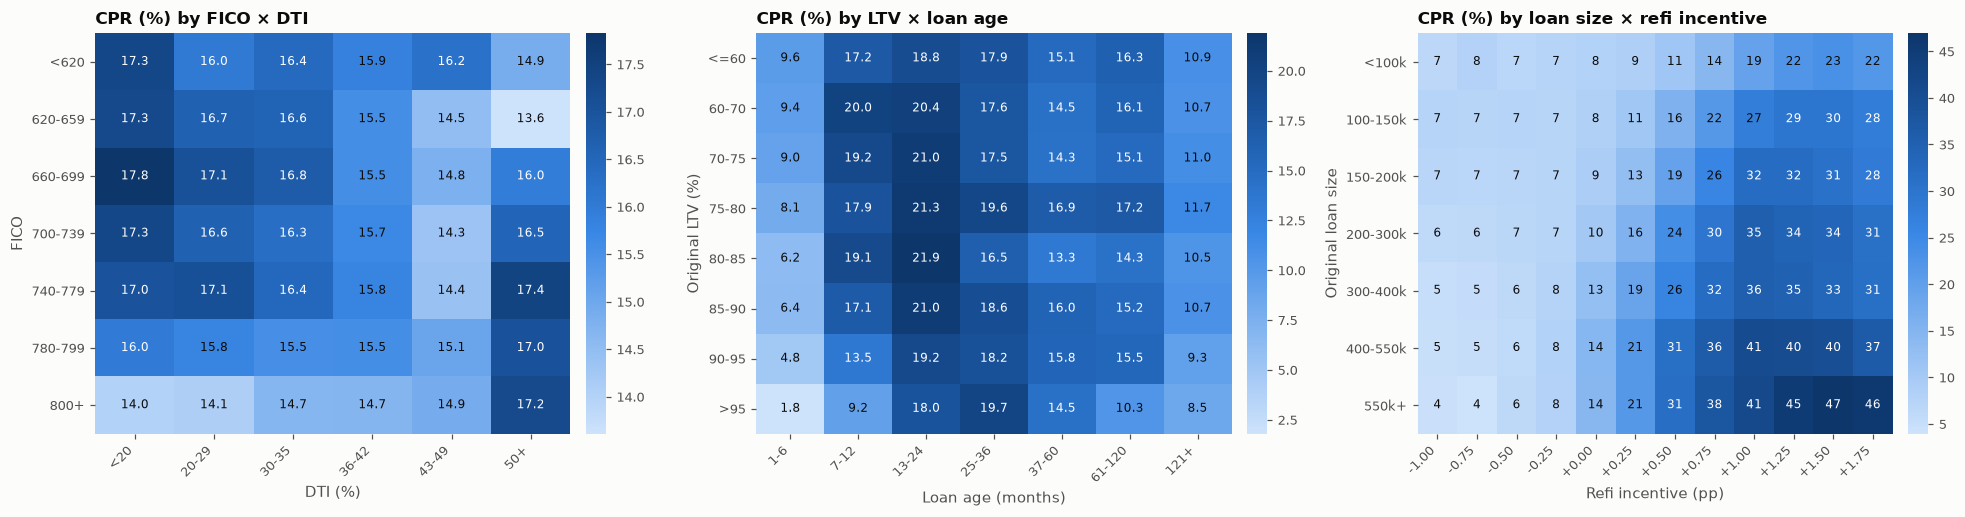

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
heat(axes[0], cpr_table(panel, ["fico_b", "dti_b"]), "fico_b", "dti_b", title="CPR (%) by FICO × DTI")
axes[0].set_xlabel("DTI (%)"); axes[0].set_ylabel("FICO")
heat(axes[1], cpr_table(panel, ["ltv_b", "age_b"]), "ltv_b", "age_b", title="CPR (%) by LTV × loan age")
axes[1].set_xlabel("Loan age (months)"); axes[1].set_ylabel("Original LTV (%)")
ui = cpr_table(panel.filter(pl.col("incentive").is_between(-1.0, 2.0, closed="left")), ["upb_b", "inc_b"])
heat(axes[2], ui, "upb_b", "inc_b", fmt="{:.0f}", title="CPR (%) by loan size × refi incentive")
axes[2].set_xlabel("Refi incentive (pp)"); axes[2].set_ylabel("Original loan size")
fig.tight_layout()

### 5d. Is the 1D FICO/LTV effect real or mix? Within-month comparison

Pooled 1D curves mix vintages and rate environments. For example, high-LTV loans are concentrated in some vintages. A simple check is to compute each bucket's CPR **relative to all loans in the same reporting month and incentive bucket**, then average those ratios over cells weighted by exposure. A value of 1.0 means "as fast as comparable loans".

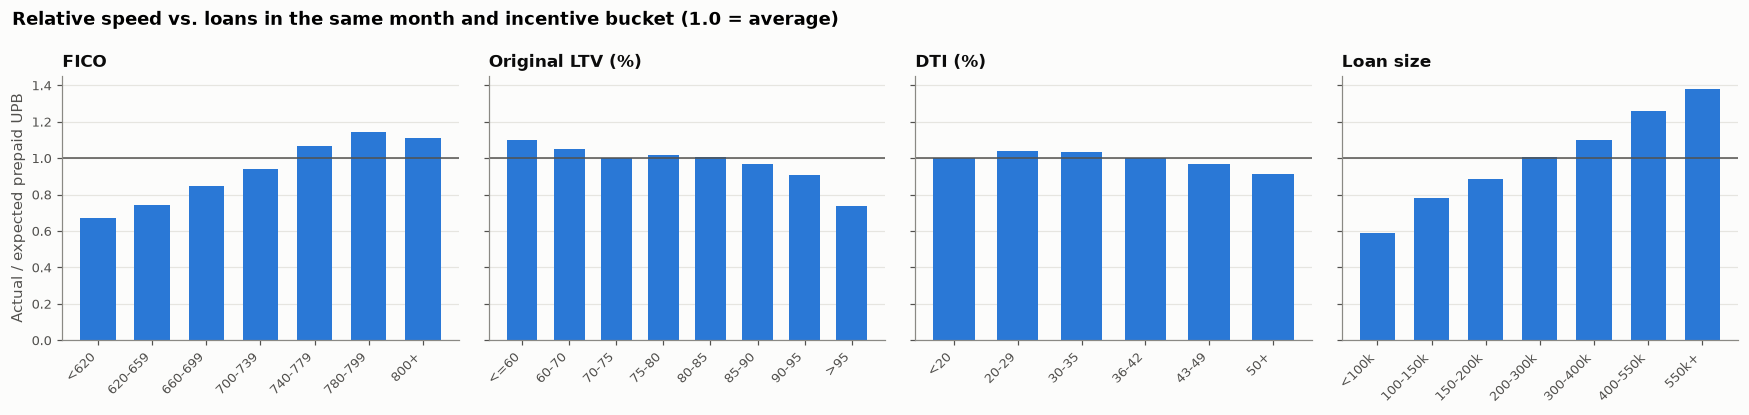

In [18]:
def relative_speed(frame, col):
    cell = ["t", "inc_b"]
    g = (frame.filter(pl.col(col).is_not_null() & pl.col("inc_b").is_not_null())
         .group_by(cell + [col]).agg(exp=pl.col("exposure").sum(), pre=pl.col("prepaid").sum()))
    base = g.group_by(cell).agg(base_smm=pl.col("pre").sum() / pl.col("exp").sum())
    g = g.join(base, on=cell).with_columns(expected=pl.col("exp") * pl.col("base_smm"))
    return (g.group_by(col).agg(actual=pl.col("pre").sum(), expected=pl.col("expected").sum())
             .with_columns(rel_speed=pl.col("actual") / pl.col("expected")).sort(col))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (col, title) in zip(axes, [("fico_b", "FICO"), ("ltv_b", "Original LTV (%)"), ("dti_b", "DTI (%)"), ("upb_b", "Loan size")]):
    r = relative_speed(panel, col)
    x = np.arange(r.height)
    ax.bar(x, r["rel_speed"], color=SERIES[0], width=0.65)
    ax.axhline(1, color=INK_2, lw=1)
    ax.set_xticks(x, r[col].cast(pl.Utf8), rotation=45, ha="right")
    ax.set_title(title, loc="left")
axes[0].set_ylabel("Actual / expected prepaid UPB")
fig.suptitle("Relative speed vs. loans in the same month and incentive bucket (1.0 = average)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

## 6. Summary tables (for reference)

In [19]:
summary_1d = pl.concat([
    cpr_table(panel, c).select(pl.lit(c).alias("feature"), pl.col(c).cast(pl.Utf8).alias("bucket"),
                              "cpr", "cpr_lo", "cpr_hi", "loan_months", "payoffs", (100 * pl.col("bal_share")).round(1).alias("bal_pct"))
    for c, _ in ONE_D
])
summary_1d.with_columns(pl.col("cpr", "cpr_lo", "cpr_hi").round(2))

feature,bucket,cpr,cpr_lo,cpr_hi,loan_months,payoffs,bal_pct
str,str,f64,f64,f64,u32,u32,f64
"""fico_b""","""<620""",15.91,15.55,16.26,443456,6089,1.3
"""fico_b""","""620-659""",15.46,15.26,15.65,1431372,19615,5.0
"""fico_b""","""660-699""",15.93,15.79,16.08,2826411,40561,11.2
"""fico_b""","""700-739""",15.75,15.63,15.87,4287288,61928,19.4
"""fico_b""","""740-779""",16.04,15.94,16.13,6099450,89971,29.9
"""fico_b""","""780-799""",15.64,15.51,15.76,3869023,54776,20.0
"""fico_b""","""800+""",14.61,14.47,14.75,2622537,33925,13.1
"""ltv_b""","""<=60""",15.58,15.46,15.7,3824939,53211,15.9
"""ltv_b""","""60-70""",16.09,15.95,16.23,2759762,39320,13.0


## 7. Takeaways

**Data processed:** about 8.4 GB of the ~950 GB zip (the first 80 MB of each of 105 quarterly files, 2000Q1-2026Q1). That's 746k loans and 29.5M loan-months read. The analysis uses the **605k 30-year loans: 21.7M loan-months and 308k payoffs**. Overall CPR is 15.7%.

We ran **15 one-dimensional and 9 two-dimensional cuts**; the strongest results are below.

### 1D
- **Refi incentive dominates:** CPR goes from about 5% when refinancing doesn't pay to about 33% at +1 point.
- **Loan size:** bigger loans prepay faster (0.6× for <$100k up to 1.4× for $550k+, vs. comparable loans).
- **LTV:** >95 LTV is slowest (12% CPR vs. 16-17%), mostly in the first year.
- **FICO looks flat when pooled (15-16%), but this is a mix effect.** Against comparable loans it rises from 0.67× (<620) to 1.15× (780+).
- **Loan age:** speeds ramp up over the first two years (8% → 20% CPR).

### 2D
- **FICO × incentive:** when refinancing pays, 780+ borrowers reach about 40% CPR vs. about 24% for <680. When it doesn't, low FICO is slightly faster.
- **Loan size × incentive:** in the money, large loans hit about 45% CPR vs. about 22% for small loans.
- **LTV × age:** high-LTV loans are very slow early (2% CPR in months 1-6 for >95 LTV) and catch up by year 2-3.
- **Age × incentive (burnout):** loans older than 5 years peak at about 24% CPR vs. about 42% for 1-3-year-old loans.
